# 10x Atera whole-transcriptome datasets: a first look across sections

Data: 10x Genomics, CC BY 4.0.

This primer loads every 10x Atera whole-transcriptome section in one spatialdata-db catalog release, runs the same
quality control on each, integrates them with Harmony on a GPU, and gives a cursory view of the cell populations
and where they sit in each tissue.

## Caveats

- This is a first look, not an analysis. The same rules apply to every section. Three settings were chosen on a
  100,000-cell test after a first version gave a cluster of low-quality cells: the quality floor of a quarter of each
  section's median counts, the scaling before PCA, and the label threshold. They are stated where they are used.
- Cell types are automated and cursory: broad marker-gene scores per cell, with "unassigned" where no class stands
  out. They are not validated, and fine cell states are not resolved.
- Each tissue has one section, and breast has two (one FF, one FFPE), so tissue, section and preservation can't be
  separated.

In [1]:
import hashlib
import json
import os
import warnings
from importlib.metadata import version
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm in a non-widget kernel
warnings.filterwarnings("ignore", message="Converting `region_key: region` to categorical dtype")  # spatialdata, per table built below

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rapids_singlecell as rsc
import scanpy as sc
import spatialdata as sd
import spatialdata_plot  # noqa: F401  (registers sdata.pl)

import sddb

import logging

logging.getLogger("ome_zarr").setLevel(logging.WARNING)  # its INFO lines per image read add tens of kB to the outputs

CATALOG_VERSION = "2026-11-12"  # pinned catalog release (tag catalog-2026-11-12)
OUT = Path(os.environ.get("ATERA_OUT", "atera_out"))  # site tables and figures, not in git (see .gitignore)
OUT.mkdir(exist_ok=True)
SEED, N_HVG, N_PCS, SAMPLE = 0, 2_000, 50, 100_000
LOW_DEPTH, N_NEIGHBORS, RESOLUTION, LABEL_MARGIN = 0.25, 30, 1.0, 0.1  # chosen on a 100,000-cell test (qc_sample_check.py, core_qc.py); see the QC and label sections
RULES = f"qc: 50/20, 5 MAD per section, {LOW_DEPTH} x median; hvg seurat_v3 per section by median rank; scale 10; nn {N_NEIGHBORS}; leiden {RESOLUTION}; label margin {LABEL_MARGIN}"
CREDIT = "Data: 10x Genomics, CC BY 4.0"
sc.set_figure_params(dpi=80, facecolor="white", fontsize=9)
plt.rcParams.update({"font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8})
W = 1600 / 150  # hero figures: 1600 px wide at 150 dpi, so text has one size across them


def credit(fig):
    """The data credit as a small footer, clear of the panel titles."""
    fig.text(0.01, 0.005, CREDIT, fontsize=7, color="#555555", ha="left", va="bottom")
print("sddb", sddb.__version__, "| rapids-singlecell", rsc.__version__, "| scanpy", version("scanpy"), "| catalog", CATALOG_VERSION)

sddb 0.1.4 | rapids-singlecell 0.18.1 | scanpy 1.12.5 | catalog 2026-11-12


## Cohort

One query returns every Atera section in the release. Each row carries its tissue and preservation.

In [2]:
ZARRS = os.environ.get("ATERA_ZARRS")  # pre-release only: folder of converted candidates (<sddb_id>/sdata/v1.zarr)
ROWS = os.environ.get("ATERA_ROWS")  # pre-release only: JSON rows of live records by uid (uid pins the bytes), checked against the release later
if ROWS:
    from sddb.cohort import SpatialDataCohort

    atera = SpatialDataCohort(pd.DataFrame(json.loads(Path(ROWS).read_text())))
    cohort = atera.members[["uid", "canonical_key", "tissue", "disease", "preservation_method", "n_obs", "n_features", "license"]]
elif ZARRS:
    rows = []
    for f in sorted(Path(ZARRS).glob("*/candidate.json")):
        d = json.loads(f.read_text())
        rows.append({"uid": f.parent.name, "canonical_key": d["canonical_key"], "tissue": d["tissue"]["text"], "disease": d["disease"]["text"],
                     "preservation_method": None, "n_obs": None, "n_features": None, "license": "CC-BY-4.0"})
    cohort = pd.DataFrame(rows)
else:
    catalog = sddb.Catalog(version=CATALOG_VERSION)
    print("catalog release", catalog.release, "|", catalog.url)
    atera = catalog.query(technology="10x_atera")  # catalog schema 3 stores technology ids (technology.json)
    cohort = atera.members[["uid", "canonical_key", "tissue", "disease", "preservation_method", "n_obs", "n_features", "license"]]
cohort = cohort.assign(preservation=cohort["preservation_method"].replace({"Fresh Frozen": "FF"}).fillna(cohort["canonical_key"].str.extract(r"-(ffpe|ff)-", expand=False).str.upper()))  # the release spells FF out ("Fresh Frozen"); the -ff- keys and the figures use FF
EXPECT = os.environ.get("ATERA_EXPECT")  # release check: the pre-release rows the cache was built from
if EXPECT and not ROWS:
    want = pd.DataFrame(json.loads(Path(EXPECT).read_text())).set_index("canonical_key")[["tissue", "disease", "preservation_method"]]
    got = cohort.set_index("canonical_key")[["tissue", "disease", "preservation"]].set_axis(want.columns, axis=1)
    assert sorted(got.index) == sorted(want.index) and got.loc[want.index].astype(str).equals(want.astype(str)), (got, want)
cohort.to_csv(OUT / "cohort.csv", index=False)
keys = dict(zip(cohort["uid"], cohort["canonical_key"]))
cohort

catalog release 2026-11-12 | https://github.com/theislab/spatialdata-db-client/releases/download/catalog-2026-11-12/catalog.parquet


,uid,canonical_key,tissue,disease,preservation_method,n_obs,n_features,license,preservation
0,Oc0RVwT6WdZXOkAv0000,10x:atera-wta-ff-human-breast-cancer,breast,breast cancer,Fresh Frozen,485985,24677,CC-BY-4.0,FF
1,jCLxdY1tWKmbfWOB0001,10x:atera-wta-ffpe-human-breast-cancer,breast,breast cancer,FFPE,170057,18028,CC-BY-4.0,FFPE
2,HJozpYNEQ652yzNM0001,10x:atera-wta-ffpe-human-cervical-cancer,uterine cervix,squamous cell carcinoma,FFPE,717576,18028,CC-BY-4.0,FFPE
3,kQH40cwY13w2E7730000,10x:atera-wta-ff-human-nd-brain,brain,normal,Fresh Frozen,91431,24677,CC-BY-4.0,FF
4,0GBPeU69wyALRyd10000,10x:atera-wta-ff-human-crc,colon,colorectal adenocarcinoma,Fresh Frozen,446777,24677,CC-BY-4.0,FF
5,wp9BiiVuas1XuPXO0001,10x:atera-wta-ffpe-human-nd-kidney,kidney,normal,FFPE,399120,24674,CC-BY-4.0,FFPE


Each section is read through the client: only the cell table and the cell shapes it annotates (and the H&E where
there is one), not the transcripts. Sections are processed one at a time, in two passes, so only one full count matrix is
in memory at once: the first pass runs QC and finds each section's variable genes, the second keeps the joint
genes only.

In [3]:
MARKERS = {
    "epithelial": ["EPCAM", "KRT8", "KRT18", "KRT19", "CDH1", "KRT5", "KRT14", "KRT17"],
    "T/NK": ["CD3E", "CD3D", "CD2", "NKG7", "GZMA"],
    "B/plasma": ["MS4A1", "CD79A", "JCHAIN", "MZB1"],
    "myeloid": ["CD68", "CD14", "LYZ", "CSF1R", "C1QA"],
    "fibroblast": ["COL1A1", "COL1A2", "DCN", "LUM", "PDGFRA"],
    "smooth muscle/pericyte": ["ACTA2", "MYH11", "RGS5", "TAGLN"],
    "endothelial": ["PECAM1", "VWF", "CLDN5", "KDR"],
    "neuron": ["SNAP25", "RBFOX3", "SYT1", "GAD1", "SLC17A7"],
    "astrocyte": ["GFAP", "AQP4", "SLC1A3"],
    "oligodendrocyte": ["MBP", "PLP1", "MOG"],
    "microglia": ["P2RY12", "CX3CR1", "TMEM119"],
}
BRAIN_ONLY = {"neuron", "astrocyte", "oligodendrocyte", "microglia"}  # only offered for brain sections
SHOW_GENES = ["EPCAM", "SNAP25"]  # kept on the light tables for the gene-on-tissue figure


def load(uid):
    if ZARRS:
        s = sd.read_zarr(Path(ZARRS) / uid / "sdata" / "v1.zarr", selection=("tables", "shapes", "images"))
        for k in [k for k in s.images if k != "he_image"]:
            del s.images[k]
    else:
        ds = next(iter(atera.where(atera.members["uid"] == uid)))
        region = ds.to_sdata(elements=["tables/table"]).tables["table"].uns["spatialdata_attrs"]["region"]
        region = region if isinstance(region, str) else region[0]
        present = ds.elements()
        shapes = f"shapes/{region}" if f"shapes/{region}" in present else "shapes/cell_boundaries"  # some tables annotate cell_labels
        els = ["tables/table", shapes] + [e for e in present if e == "images/he_image"]
        s = ds.to_sdata(elements=els)
    a = s.tables["table"]
    a.obs_names = a.obs_names.astype(str)
    ftype = next((c for c in ("feature_types", "feature_type") if c in a.var), None)  # the column name differs between releases
    if ftype:
        a = a[:, a.var[ftype].astype(str) == "Gene Expression"].copy()
    if "feature_name" in a.var:  # some tables are indexed by Ensembl id with the symbol in feature_name: use symbols throughout
        a.var_names = a.var["feature_name"].astype(str).values
    a.var_names = a.var_names.astype(str)
    a.var_names_make_unique()
    a.X = a.X.astype(np.float32)  # some sections store integer counts; GPU sparse matrices need floats
    # the catalog tables also carry a csc_counts layer (the same counts, column-compressed); X depends on it, so it stays
    return a, s


def low_tail(x, k=5):
    """More than k median absolute deviations below the median."""
    med = np.median(x)
    return x < med - k * np.median(np.abs(x - med))


def qc_mark(a):
    """QC metrics and the low-quality flag of every cell of one section (see the QC section). Flagged cells stay in the data."""
    sc.pp.calculate_qc_metrics(a, percent_top=None, log1p=True, inplace=True)
    o = a.obs
    o["low_quality"] = ((o["total_counts"] < 50) | (o["n_genes_by_counts"] < 20) | low_tail(o["log1p_total_counts"].to_numpy())
                        | low_tail(o["log1p_n_genes_by_counts"].to_numpy()) | (o["total_counts"] < LOW_DEPTH * np.median(o["total_counts"])))
    return a


# The GPU part (QC, variable genes, Harmony, UMAP, Leiden) is cached in OUT/cache with its sha256 and the uids it used. A
# rerun on the same uids loads it and redraws everything else; any other uid set recomputes it.
CACHE = OUT / "cache"
UIDS = sorted(cohort["uid"])


def sha256(f):
    h = hashlib.sha256()
    with open(f, "rb") as fh:
        for b in iter(lambda: fh.read(1 << 24), b""):
            h.update(b)
    return h.hexdigest()


meta = json.loads((CACHE / "heavy.json").read_text()) if (CACHE / "heavy.json").exists() else {}
HIT = meta.get("uids") == UIDS and meta.get("rules") == RULES and all(sha256(CACHE / f) == h for f, h in meta.get("sha256", {}).items())
print("cache", "hit" if HIT else "miss", f"{OUT.name}/cache")  # relative: no machine paths in the committed outputs
if HIT:
    qc_obs = {u: d.drop(columns="uid") for u, d in pd.read_parquet(CACHE / "qc_obs.parquet").groupby("uid")}

qc_rows, hv_rank, hv_flag, gene_sets, kept, sdatas = [], {}, {}, [], {}, {}
qc_obs = qc_obs if HIT else {}
for r in cohort.itertuples():  # pass 1: QC and variable genes, one section at a time
    a, s = load(r.uid)
    if HIT:  # only the small table for the spatial figures
        a = a[a.obs_names.isin(qc_obs[r.uid].index), [x for x in SHOW_GENES if x in a.var_names]].copy()
        s.tables["table"] = a
        sdatas[r.uid] = s
        continue
    n0, g0 = a.n_obs, a.n_vars
    a = qc_mark(a)
    low = a.obs["low_quality"].to_numpy()
    qc_obs[r.uid] = a.obs[["total_counts", "n_genes_by_counts", "low_quality"]].copy()
    s.tables["table"] = a[:, [x for x in SHOW_GENES if x in a.var_names]].copy()  # small table of every cell for the spatial figures
    sdatas[r.uid] = s
    a = a[~low].copy()
    sc.pp.filter_genes(a, min_cells=10)
    kept[r.uid] = a.obs_names
    gene_sets.append(set(a.var_names))
    qc_rows.append({"dataset": r.canonical_key, "tissue": r.tissue, "preservation": r.preservation, "cells": n0, "low_quality": int(low.sum()),
                    "cells_kept": a.n_obs, "genes": g0, "genes_kept": a.n_vars, "median_counts": float(np.median(a.obs["total_counts"])),
                    "median_genes": float(np.median(a.obs["n_genes_by_counts"]))})
    sc.pp.highly_variable_genes(a, n_top_genes=N_HVG, flavor="seurat_v3")  # on the counts of the kept cells (seurat_v3 expects counts)
    hv_rank[r.uid], hv_flag[r.uid] = a.var["highly_variable_rank"], a.var["highly_variable"]
    print(r.uid, r.tissue, r.preservation, n0, "cells,", int(low.sum()), "low quality")
    del a
qc = pd.read_csv(CACHE / "qc_per_dataset.csv") if HIT else pd.DataFrame(qc_rows)
qc.to_csv(OUT / "qc_per_dataset.csv", index=False)
qc

cache hit atera_out_release/cache


2026-11-13 04:48:52 | [WARNING] no parent found for <ome_zarr.reader.Label object at 0x7f69a41792b0>: None


2026-11-13 04:49:11 | [WARNING] no parent found for <ome_zarr.reader.Label object at 0x7f6958489810>: None


2026-11-13 04:52:21 | [WARNING] no parent found for <ome_zarr.reader.Label object at 0x7f69a41c1310>: None


2026-11-13 04:52:42 | [WARNING] no parent found for <ome_zarr.reader.Label object at 0x7f69a41336f0>: None


2026-11-13 04:53:09 | [WARNING] no parent found for <ome_zarr.reader.Label object at 0x7f69a4132520>: None


2026-11-13 04:53:28 | [WARNING] no parent found for <ome_zarr.reader.Label object at 0x7f697c74ec30>: None


2026-11-13 04:54:50 | [WARNING] no parent found for <ome_zarr.reader.Label object at 0x7f69a431ef10>: None


2026-11-13 04:55:06 | [WARNING] no parent found for <ome_zarr.reader.Label object at 0x7f69a431fbd0>: None


,dataset,tissue,preservation,cells,low_quality,cells_kept,genes,genes_kept,median_counts,median_genes
0,10x:atera-wta-ff-human-breast-cancer,breast,FF,485985,66873,419112,18049,18049,6277.0,3367.0
1,10x:atera-wta-ffpe-human-breast-cancer,breast,FFPE,170057,16267,153790,18028,18022,2377.0,1694.0
2,10x:atera-wta-ffpe-human-cervical-cancer,uterine cervix,FFPE,717576,56612,660964,18028,18025,1014.0,747.0
3,10x:atera-wta-ff-human-nd-brain,brain,FF,91431,13564,77867,18049,18031,5648.0,2984.0
4,10x:atera-wta-ff-human-crc,colon,FF,446777,75228,371549,18049,18049,6186.0,3348.0
5,10x:atera-wta-ffpe-human-nd-kidney,kidney,FFPE,399120,47042,352078,18049,18045,1845.0,1380.0


## Quality control

Depth differs about sixfold between the sections (median counts per cell), so each section is judged against its
own distribution. A cell is marked low quality when it has fewer than 50 counts or 20 detected genes, when its log
counts or log genes lie more than 5 median absolute deviations below the section median (a permissive outlier rule
from the scverse best-practices book, sc-best-practices.org, Quality Control chapter), or when it has fewer than
a quarter of the section's median counts. The quarter is our judgement: on a 100,000-cell test, the cells below it
formed a cluster drawn from every section, with about half the cell area of the other cells (median 26 to 52
against 54 to 73 square micrometres) and far fewer counts per square micrometre (9 to 19 against 21 to 104). Neither
the control counts nor the segmentation method (recorded for two sections) set these cells apart. Low-quality cells stay
in the data and are counted per section below, and they are left out of the embedding and the cell types. Genes
detected in fewer than 10 kept cells of a section are dropped. Only gene features are kept (no control probes or
codewords).

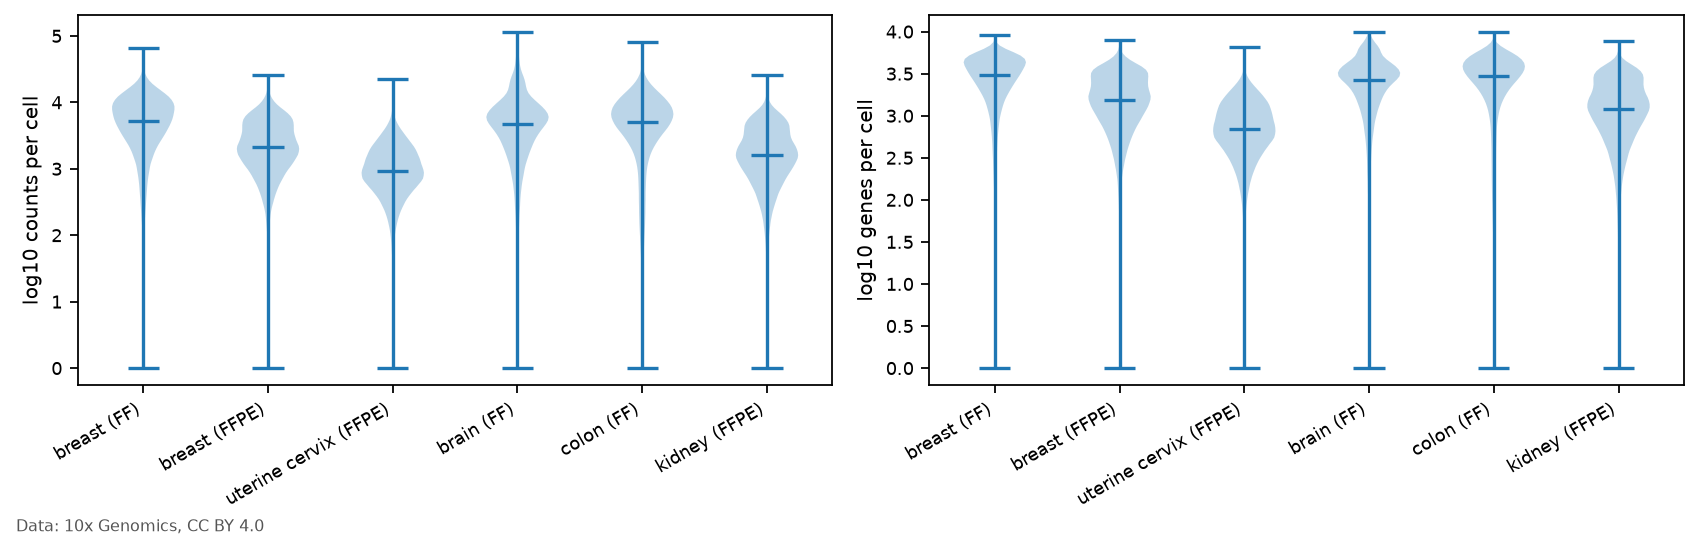

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(W, 3.4))
for ax, col, lab in zip(axs, ("total_counts", "n_genes_by_counts"), ("counts per cell", "genes per cell")):
    ax.violinplot([np.log10(qc_obs[u][col].to_numpy() + 1) for u in cohort["uid"]], showmedians=True)
    ax.set_xticks(range(1, len(cohort) + 1), cohort["tissue"] + " (" + cohort["preservation"] + ")", rotation=30, ha="right")
    ax.set_ylabel(f"log10 {lab}")
    ax.grid(False)
credit(fig)
fig.tight_layout()
fig.savefig(OUT / "fig_qc.png", dpi=150, facecolor="white")

## Embedding and Harmony

Variable genes are ranked in each section on its counts (scanpy `highly_variable_genes`, flavor `seurat_v3`), and the
2,000 with the best median rank over the sections, ties broken by the number of sections in which a gene is
variable, are kept. This is the rule scanpy documents for its `batch_key` option, which "avoids the selection of
batch-specific genes". With the broad marker genes, measured in every section, they form the joint gene set. The
joint counts are normalised to 10,000 per cell, log-transformed, scaled to unit variance per gene and clipped at 10
on the GPU, so that deep sections don't dominate the principal components. Harmony corrects the PCs for the section.
Neighbours (30 per cell), UMAP and Leiden (resolution 1.0) run on the corrected PCs. A UMAP of the uncorrected PCs is
kept for comparison.

In [5]:
if HIT:
    markers, genes = meta["markers"], meta["genes"]
else:
    shared = set.intersection(*gene_sets)
    markers = {k: [g for g in v if g in shared] for k, v in MARKERS.items()}
    # the batch_key merge of scanpy 1.12.5 (preprocessing/_highly_variable_genes.py:243-276): median of the ranks inside each
    # section's top N (others NaN), sorted by that median, then by the number of sections with the gene in the top N
    rank = pd.DataFrame(hv_rank).reindex(sorted(shared))  # genes x sections
    nb = pd.DataFrame(hv_flag).reindex(rank.index).fillna(False).astype(bool).sum(axis=1)
    order = pd.DataFrame({"median_rank": rank.median(axis=1, skipna=True), "n_sections": nb}).dropna()
    order = order.sort_values(["median_rank", "n_sections"], ascending=[True, False])
    hvg = set(order.index[:N_HVG])
    genes = sorted(hvg | {g for v in markers.values() for g in v})
    print(len(hvg), "variable genes by median rank;", len(genes), "joint genes measured in every section")
parts = []
for r in ([] if HIT else cohort.itertuples()):  # pass 2: the joint genes of the cells kept in pass 1
    a, _ = load(r.uid)
    a = a[a.obs_names.isin(kept[r.uid]), genes].copy()
    az = a.obs["azimuth_broad"].astype(str).values if "azimuth_broad" in a.obs else np.full(a.n_obs, "not available")  # 10x's labels, v1 only
    a.obs = a.obs[[]].assign(dataset=r.canonical_key, tissue=r.tissue, preservation=r.preservation, cell_id=a.obs_names, azimuth_broad=az)
    parts.append(a)
if HIT:
    adata = ad.read_h5ad(CACHE / "heavy.h5ad")
else:
    adata = ad.concat(parts, index_unique="-")
    adata.obs["dataset"] = adata.obs["dataset"].astype("category")
    adata.obs["section"] = (adata.obs["tissue"].astype(str) + " (" + adata.obs["preservation"].astype(str) + ")").astype("category")
    adata.layers["counts"] = adata.X.copy()
del parts

In [6]:
if not HIT:
    rsc.get.anndata_to_GPU(adata)
    rsc.pp.normalize_total(adata, target_sum=1e4)
    rsc.pp.log1p(adata)
    rsc.pp.scale(adata, max_value=10)  # unit variance per gene, clipped at 10 (dense: about 2M cells x 2,000 genes)
    rsc.tl.pca(adata, n_comps=N_PCS, random_state=SEED)
    rsc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, use_rep="X_pca", random_state=SEED, key_added="raw_pca")
    rsc.tl.umap(adata, neighbors_key="raw_pca", random_state=SEED)
    adata.obsm["X_umap_raw"] = adata.obsm.pop("X_umap")
    rsc.pp.harmony_integrate(adata, key="dataset", basis="X_pca", adjusted_basis="X_pca_harmony", rng=SEED)
    rsc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, use_rep="X_pca_harmony", random_state=SEED)
    rsc.tl.umap(adata, random_state=SEED)
    rsc.tl.leiden(adata, resolution=RESOLUTION, random_state=SEED)
    rsc.get.anndata_to_CPU(adata)
    adata.X = adata.layers["counts"].copy()  # keep the cache sparse; everything after reads the counts layer
    CACHE.mkdir(exist_ok=True)
    adata.write_h5ad(CACHE / "heavy.h5ad")
    qc.to_csv(CACHE / "qc_per_dataset.csv", index=False)
    pd.concat([d.assign(uid=u) for u, d in qc_obs.items()]).to_parquet(CACHE / "qc_obs.parquet")
    files = ["heavy.h5ad", "qc_per_dataset.csv", "qc_obs.parquet"]
    (CACHE / "heavy.json").write_text(json.dumps({"uids": UIDS, "rules": RULES, "genes": genes, "markers": markers, "sha256": {f: sha256(CACHE / f) for f in files}}, indent=1))
print(adata)

AnnData object with n_obs × n_vars = 2035360 × 2011
    obs: 'dataset', 'tissue', 'preservation', 'cell_id', 'azimuth_broad', 'section', 'leiden'
    var: 'mean', 'std'
    uns: 'leiden', 'log1p', 'neighbors', 'pca', 'raw_pca', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_raw', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances', 'raw_pca_connectivities', 'raw_pca_distances'
    layers: 'counts', 'csc_counts', None (.X)


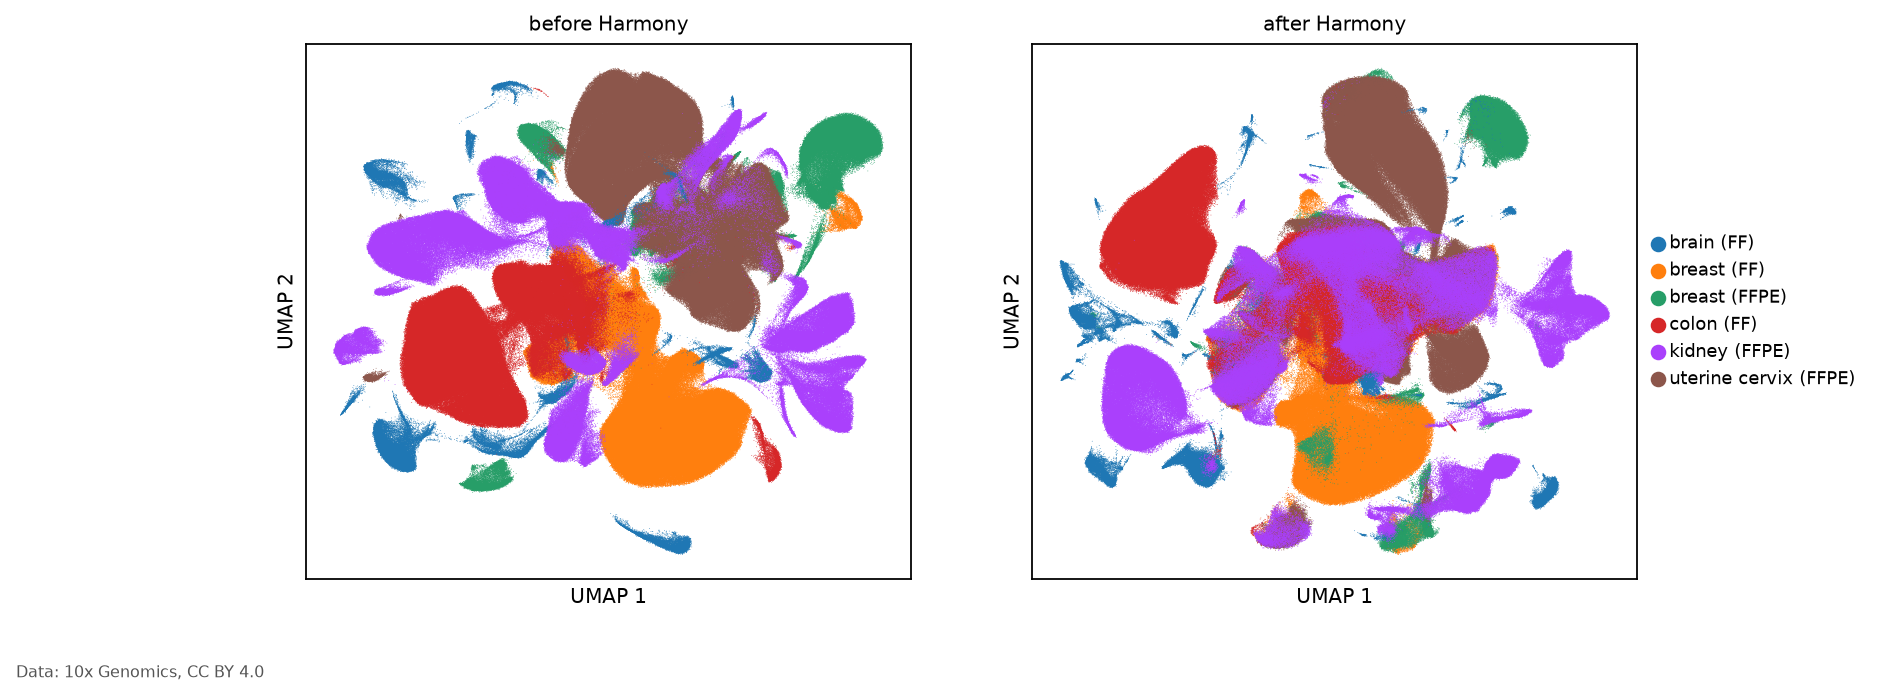

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(W, 4.4))
sc.pl.embedding(adata, basis="X_umap_raw", color="section", ax=axs[0], show=False, title="before Harmony", legend_loc=None, size=0.5)
sc.pl.embedding(adata, basis="X_umap", color="section", ax=axs[1], show=False, title="after Harmony", size=0.5)
for ax in axs:
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
credit(fig)
fig.savefig(OUT / "fig_umap_dataset.png", dpi=150, facecolor="white", bbox_inches="tight")

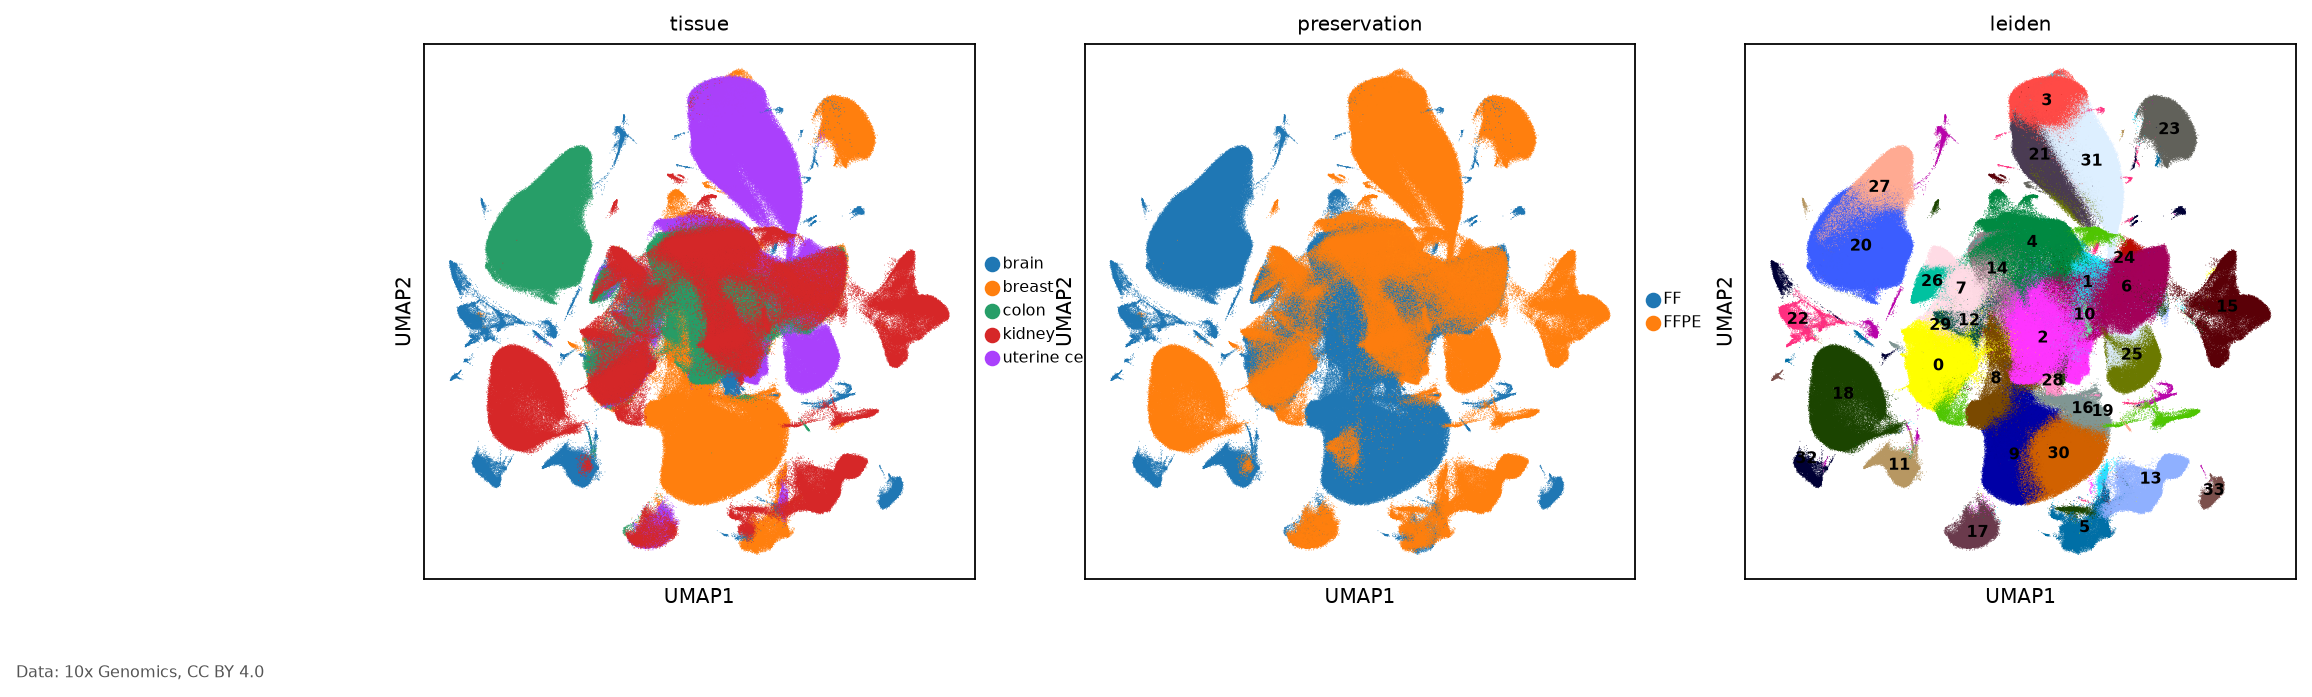

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, col in zip(axs, ("tissue", "preservation", "leiden")):
    sc.pl.umap(adata, color=col, ax=ax, show=False, size=0.5, legend_loc="on data" if col == "leiden" else "right margin", legend_fontsize=7)
credit(fig)
fig.savefig(OUT / "fig_umap_tissue_preservation_leiden.png", dpi=150, facecolor="white", bbox_inches="tight")

Per Leiden cluster: its size, the median counts of its cells, and how evenly it draws on the six sections (the
entropy of its section shares divided by the log of six: 0 for one section, 1 for an even mix). The shallowest
clusters come first.

In [9]:
depth = pd.concat([d[["total_counts"]].assign(dataset=keys[u]) for u, d in qc_obs.items()]).rename_axis("cell_id").reset_index()
obs = adata.obs[["dataset", "cell_id", "section", "leiden"]].astype({"dataset": str}).merge(depth, on=["dataset", "cell_id"], how="left")


def section_entropy(s):
    p = s.value_counts(normalize=True).to_numpy()
    p = p[p > 0]
    return float(-(p * np.log(p)).sum() / np.log(len(cohort)))


clusters = obs.groupby("leiden", observed=True).agg(cells=("cell_id", "size"), median_counts=("total_counts", "median"),
                                                     section_entropy=("section", section_entropy),
                                                     main_section=("section", lambda s: s.value_counts().index[0]))
print(len(clusters), "Leiden clusters;", int(obs["total_counts"].isna().sum()), "cells without a depth")
clusters.sort_values("median_counts").round(2).head(8)

34 Leiden clusters; 0 cells without a depth


,cells,median_counts,section_entropy,main_section
leiden,,,,
1,41589,449.0,0.53,uterine cervix (FFPE)
17,29476,808.0,0.42,uterine cervix (FFPE)
4,178140,838.0,0.68,uterine cervix (FFPE)
6,181781,903.0,0.69,uterine cervix (FFPE)
24,6354,972.0,0.02,uterine cervix (FFPE)
10,3352,1035.0,0.75,uterine cervix (FFPE)
12,26714,1037.0,0.57,uterine cervix (FFPE)
26,20820,1254.0,0.61,uterine cervix (FFPE)


## Biology: automated, cursory cell types

For each broad class, a marker-gene score per cell (scanpy `score_genes` on the log-normalised counts of the
joint gene set), z-scored over all cells. Each cell takes the class with its highest z-score among the classes
offered for its tissue (brain classes, i.e. neuron, astrocyte, oligodendrocyte and microglia, only for the brain
section), if that score is above the average (z > 0) and at least 0.1 above its second class. Otherwise the cell is
"unassigned", and no class is forced on it. The marker list has no kidney tubule markers, so many kidney epithelial
cells stay unassigned. Epithelial cells cluster by section, which is expected for tumour and organ epithelium.

In [10]:
lognorm = adata.copy()
lognorm.X = lognorm.layers["counts"].copy()
sc.pp.normalize_total(lognorm, target_sum=1e4)
sc.pp.log1p(lognorm)
scores = pd.DataFrame(index=adata.obs_names)
for k, g in markers.items():
    if g:
        sc.tl.score_genes(lognorm, g, score_name=k, random_state=SEED)
        scores[k] = lognorm.obs[k]
del lognorm
z = (scores - scores.mean()) / scores.std()
is_brain = adata.obs["tissue"].astype(str).str.contains("brain|hippocamp|cortex", case=False).to_numpy()
z.loc[~is_brain, [c for c in z.columns if c in BRAIN_ONLY]] = -np.inf
top = np.sort(z.to_numpy(), axis=1)
assigned = (top[:, -1] > 0) & (top[:, -1] - top[:, -2] >= LABEL_MARGIN)
PALETTE = dict(zip(list(MARKERS) + ["unassigned", "low quality"], ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2",
                                                                    "#17becf", "#bcbd22", "#7f7f7f", "#aec7e8", "#d9d9d9", "#525252"]))  # one colour per class
label = z.idxmax(axis=1).where(assigned, "unassigned")
adata.obs["cell_type"] = pd.Categorical(label, categories=[c for c in PALETTE if c in set(label)])
adata.uns["cell_type_colors"] = [PALETTE[c] for c in adata.obs["cell_type"].cat.categories]
pd.crosstab(adata.obs["cell_type"], adata.obs["section"])

section,brain (FF),breast (FF),breast (FFPE),colon (FF),kidney (FFPE),uterine cervix (FFPE)
cell_type,,,,,,
epithelial,0,166936,58707,241253,76747,131912
T/NK,94,23513,8051,13038,22918,104933
B/plasma,5,10121,10751,5748,12824,59051
myeloid,164,58736,7393,29590,47165,80872
fibroblast,68,46534,20427,46266,23817,91501
smooth muscle/pericyte,1383,27078,17021,20343,54263,42250
endothelial,5810,35322,17087,8322,48566,36551
neuron,24219,0,0,0,0,0
astrocyte,15711,0,0,0,0,0


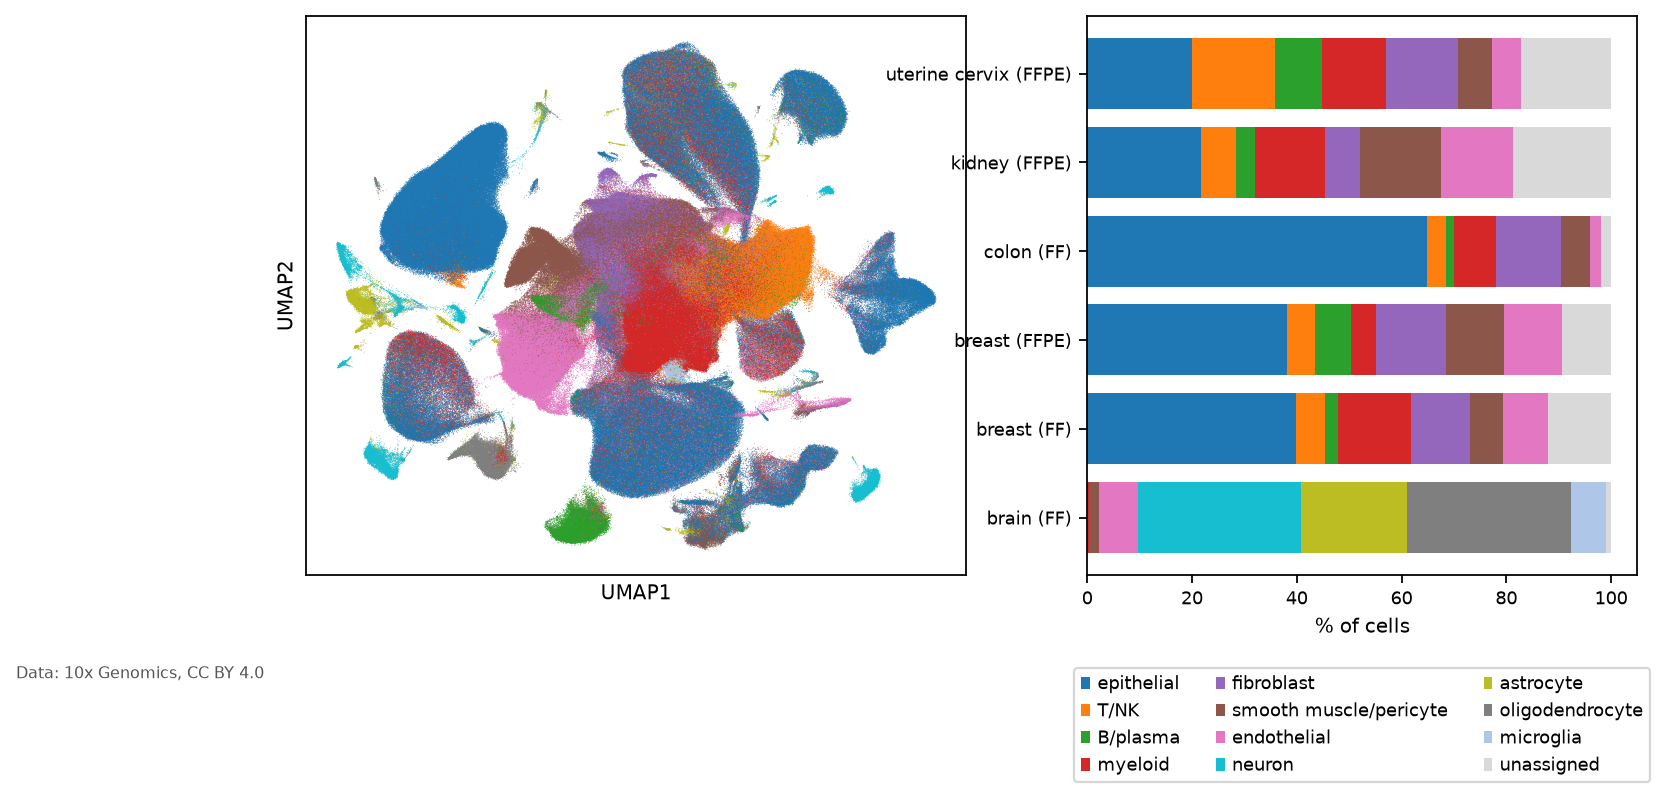

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(W, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
under = np.argsort(adata.obs["cell_type"].astype(str).values != "unassigned", kind="stable")  # unassigned drawn first, underneath
sc.pl.umap(adata[under], color="cell_type", ax=axs[0], show=False, size=0.5, title="", legend_loc=None, sort_order=False)
colors = dict(zip(adata.obs["cell_type"].cat.categories, adata.uns["cell_type_colors"]))
frac = pd.crosstab(adata.obs["section"], adata.obs["cell_type"], normalize="index") * 100  # the six sections, as everywhere on the page
frac.plot.barh(stacked=True, ax=axs[1], width=0.8, color=[colors[c] for c in frac.columns])
axs[1].set_xlabel("% of cells")
axs[1].set_ylabel("")
axs[1].grid(False)
axs[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
credit(fig)
fig.savefig(OUT / "fig_cell_types.png", dpi=150, facecolor="white", bbox_inches="tight")

### Our cursory types next to 10x's labels

The v1 datasets ship with 10x's own broad cell labels (`azimuth_broad`). The table below crosses them with the
cursory types above, for the sections that have them. Agreement here is descriptive: for each 10x label, the
cursory type most of its cells received counts as its match, and the agreement of a section is the share of its
cells whose cursory type is that match. It is a quick consistency check of the cursory labels, not a benchmark.
Every random step uses the fixed seed `SEED`.

                                      agreement
dataset                                        
10x:atera-wta-ff-human-breast-cancer      0.617
10x:atera-wta-ff-human-crc                0.848
10x:atera-wta-ff-human-nd-brain           0.683
10x:atera-wta-ffpe-human-nd-kidney        0.519
Across the 4 sections with 10x labels, 66% of cells get the cursory type that most cells of their 10x label get.


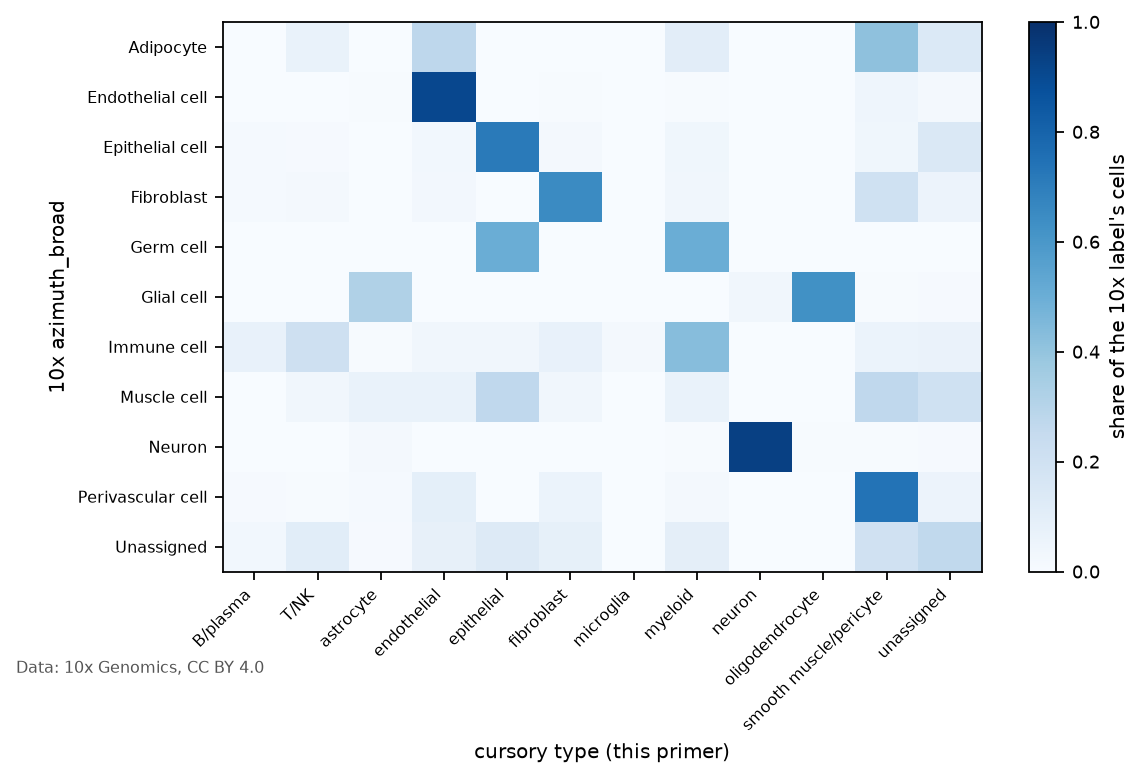

In [12]:
has_az = ~adata.obs["azimuth_broad"].astype(str).isin(["not available", "nan"])
if has_az.any():
    o = adata.obs.loc[has_az, ["dataset", "azimuth_broad", "cell_type"]].astype(str)
    # each 10x label is matched to the type most of its assigned cells get, so an unassigned cell never agrees
    match = o[o["cell_type"] != "unassigned"].groupby("azimuth_broad")["cell_type"].agg(lambda c: c.value_counts().index[0])
    o["agree"] = o["cell_type"].values == o["azimuth_broad"].map(match).values
    agreement = o.groupby("dataset")["agree"].mean().rename("agreement").to_frame()
    agreement.to_csv(OUT / "cell_types_vs_10x.csv")
    ct = pd.crosstab(o["azimuth_broad"], o["cell_type"], normalize="index")
    fig, ax = plt.subplots(figsize=(1 + 0.55 * ct.shape[1], 1 + 0.32 * ct.shape[0]))
    im = ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(ct.shape[1]), ct.columns, rotation=45, ha="right", fontsize=7)
    ax.set_yticks(range(ct.shape[0]), ct.index, fontsize=7)
    ax.set_xlabel("cursory type (this primer)")
    ax.set_ylabel("10x azimuth_broad")
    ax.grid(False)
    fig.colorbar(im, ax=ax, label="share of the 10x label's cells")
    credit(fig)
    fig.savefig(OUT / "fig_cell_types_vs_10x.png", dpi=150, facecolor="white", bbox_inches="tight")
    print(agreement.round(3).to_string())
    print(f"Across the {o['dataset'].nunique()} sections with 10x labels, {o['agree'].mean():.0%} of cells get the cursory type that most "
          "cells of their 10x label get.")

### Cell types in space

The labels go back onto each section's cell circles and are drawn with spatialdata-plot.

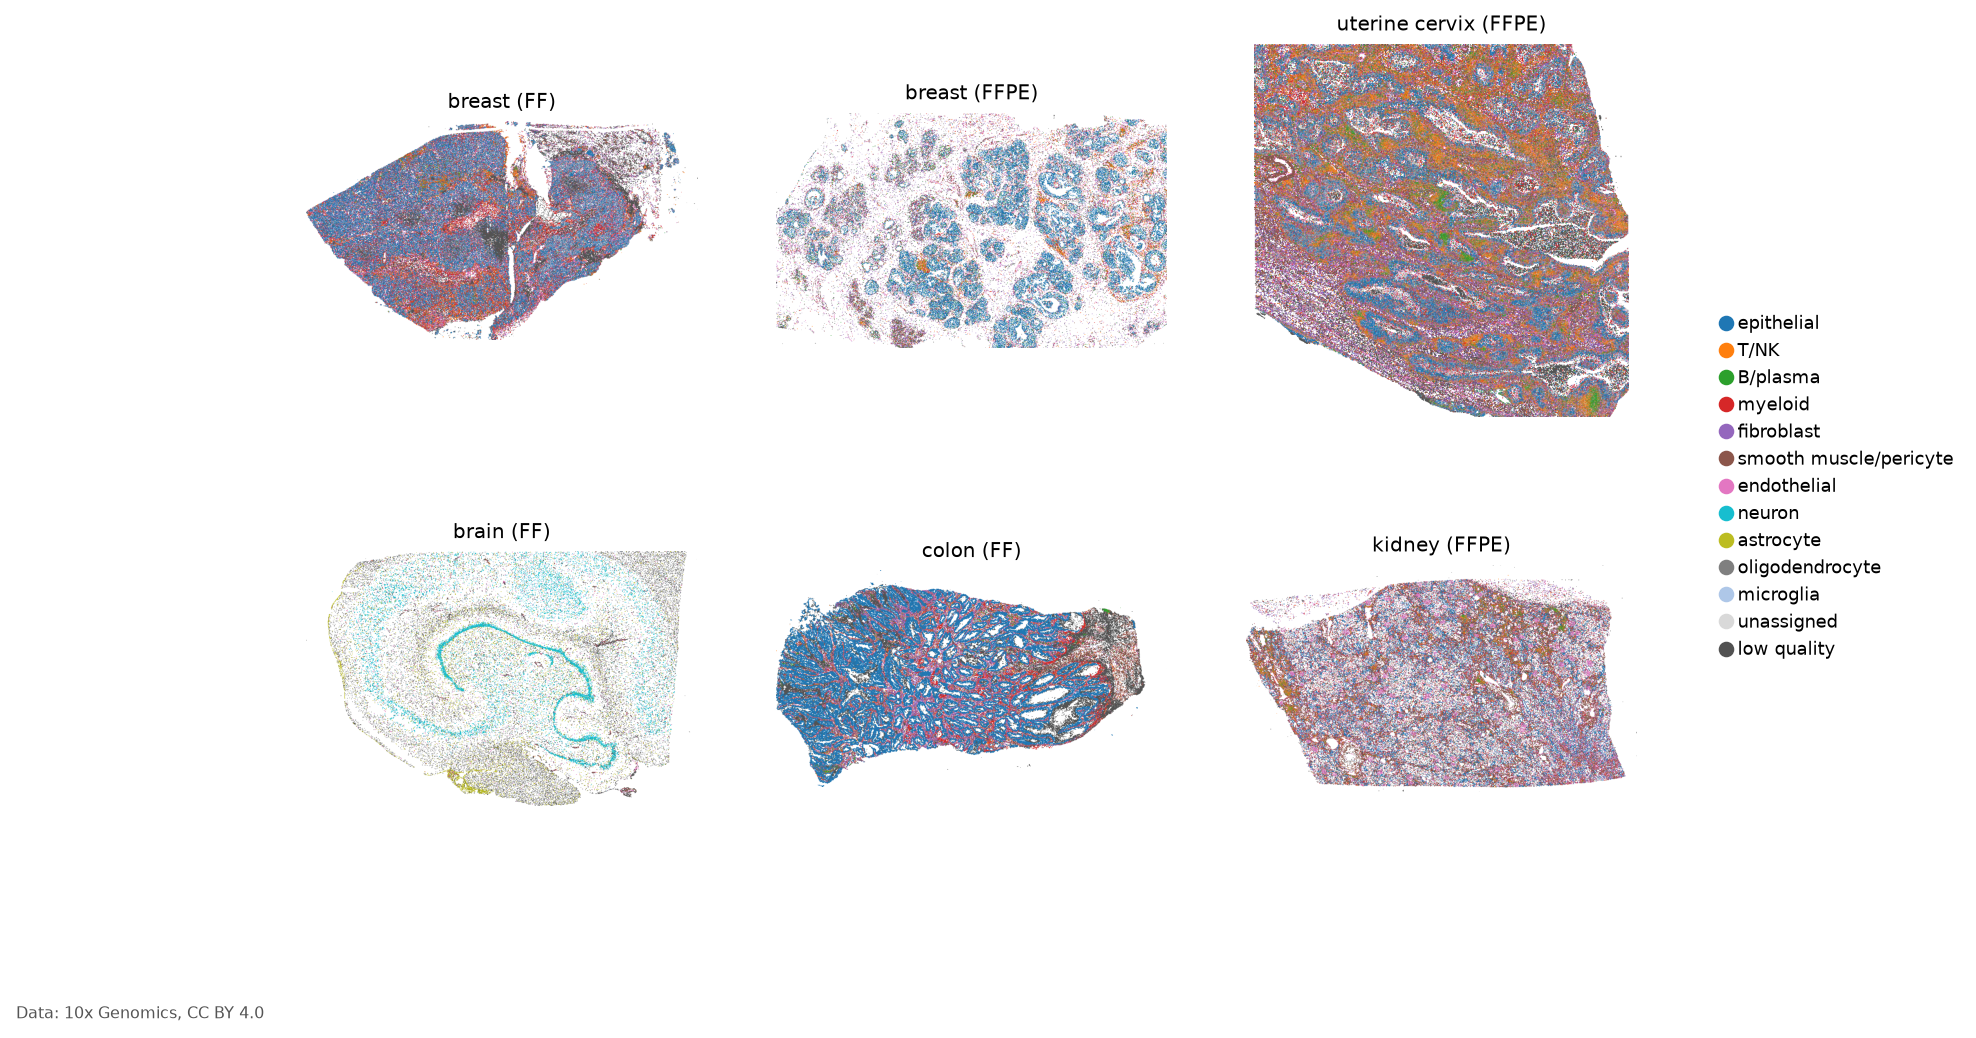

In [13]:
from spatialdata.models import TableModel  # noqa: E402


def shapes_table(s, extra_obs=None):
    """Point the light table at a shapes element: the one it annotates, else cell_boundaries matched by cell_id (some
    sections annotate the cell label image, which is not loaded here). Returns the shapes name, or None."""
    t = s.tables["table"]
    attrs = t.uns["spatialdata_attrs"]
    region = attrs["region"] if isinstance(attrs["region"], str) else attrs["region"][0]
    if region in s.shapes:
        key, rkey = attrs["instance_key"], attrs["region_key"]
    else:
        region, key, rkey = "cell_boundaries", "cell_id", "region"
        if region not in s.shapes or "cell_id" not in t.obs:
            return None
        ids = t.obs["cell_id"].astype(str)
        if ids.isin(s.shapes[region].index.astype(str)).mean() < 0.9:
            return None
        s.shapes[region].index = s.shapes[region].index.astype(str)
        t.obs["cell_id"], t.obs["region"] = ids.values, region
    if extra_obs is not None:
        for c, v in extra_obs.items():
            t.obs[c] = v
    s.tables["table"] = TableModel.parse(t, region=region, region_key=rkey, instance_key=key, overwrite_metadata=True)
    return region


n = len(cohort)
ncol = min(n, 3)
nrow = -(-n // ncol)


def grid():
    fig, axs = plt.subplots(nrow, ncol, figsize=(W, W / ncol * 0.95 * nrow), squeeze=False)
    for ax in axs.ravel()[n:]:
        ax.set_axis_off()
    return fig, axs.ravel()[:n]


fig, axs = grid()
cats = list(adata.obs["cell_type"].cat.categories) + ["low quality"]
colors["low quality"] = PALETTE["low quality"]
for i, (ax, (u, s)) in enumerate(zip(axs, sdatas.items())):
    obs = adata.obs[adata.obs["dataset"] == keys[u]].set_index("cell_id")
    t = s.tables["table"]
    ct = obs["cell_type"].astype(str).reindex(t.obs_names).fillna("low quality")  # cells left out of the embedding are drawn as low quality
    region = shapes_table(s, {"cell_type": pd.Categorical(ct.values, categories=cats)})
    if region is None:
        ax.set_axis_off()
        ax.set_title(f"{obs['tissue'].iloc[0]}: no cell shapes to draw")
        continue
    s.pl.render_shapes(region, color="cell_type", groups=cats, palette=[colors[c] for c in cats], table_name="table", method="datashader", fill_alpha=1.0).pl.show(
        ax=ax, title=f"{obs['tissue'].iloc[0]} ({obs['preservation'].iloc[0]})", legend_loc=None)
    ax.set_axis_off()
# one legend for all sections (a per-panel legend lists only that section's types)
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=colors[c], label=c) for c in cats], loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
credit(fig)
fig.savefig(OUT / "fig_cell_types_space.png", dpi=150, facecolor="white", bbox_inches="tight")

### One gene on the tissue

One marker per section (SNAP25 in brain, EPCAM elsewhere), drawn on the H&E where the section has one, else on
the cell circles alone.

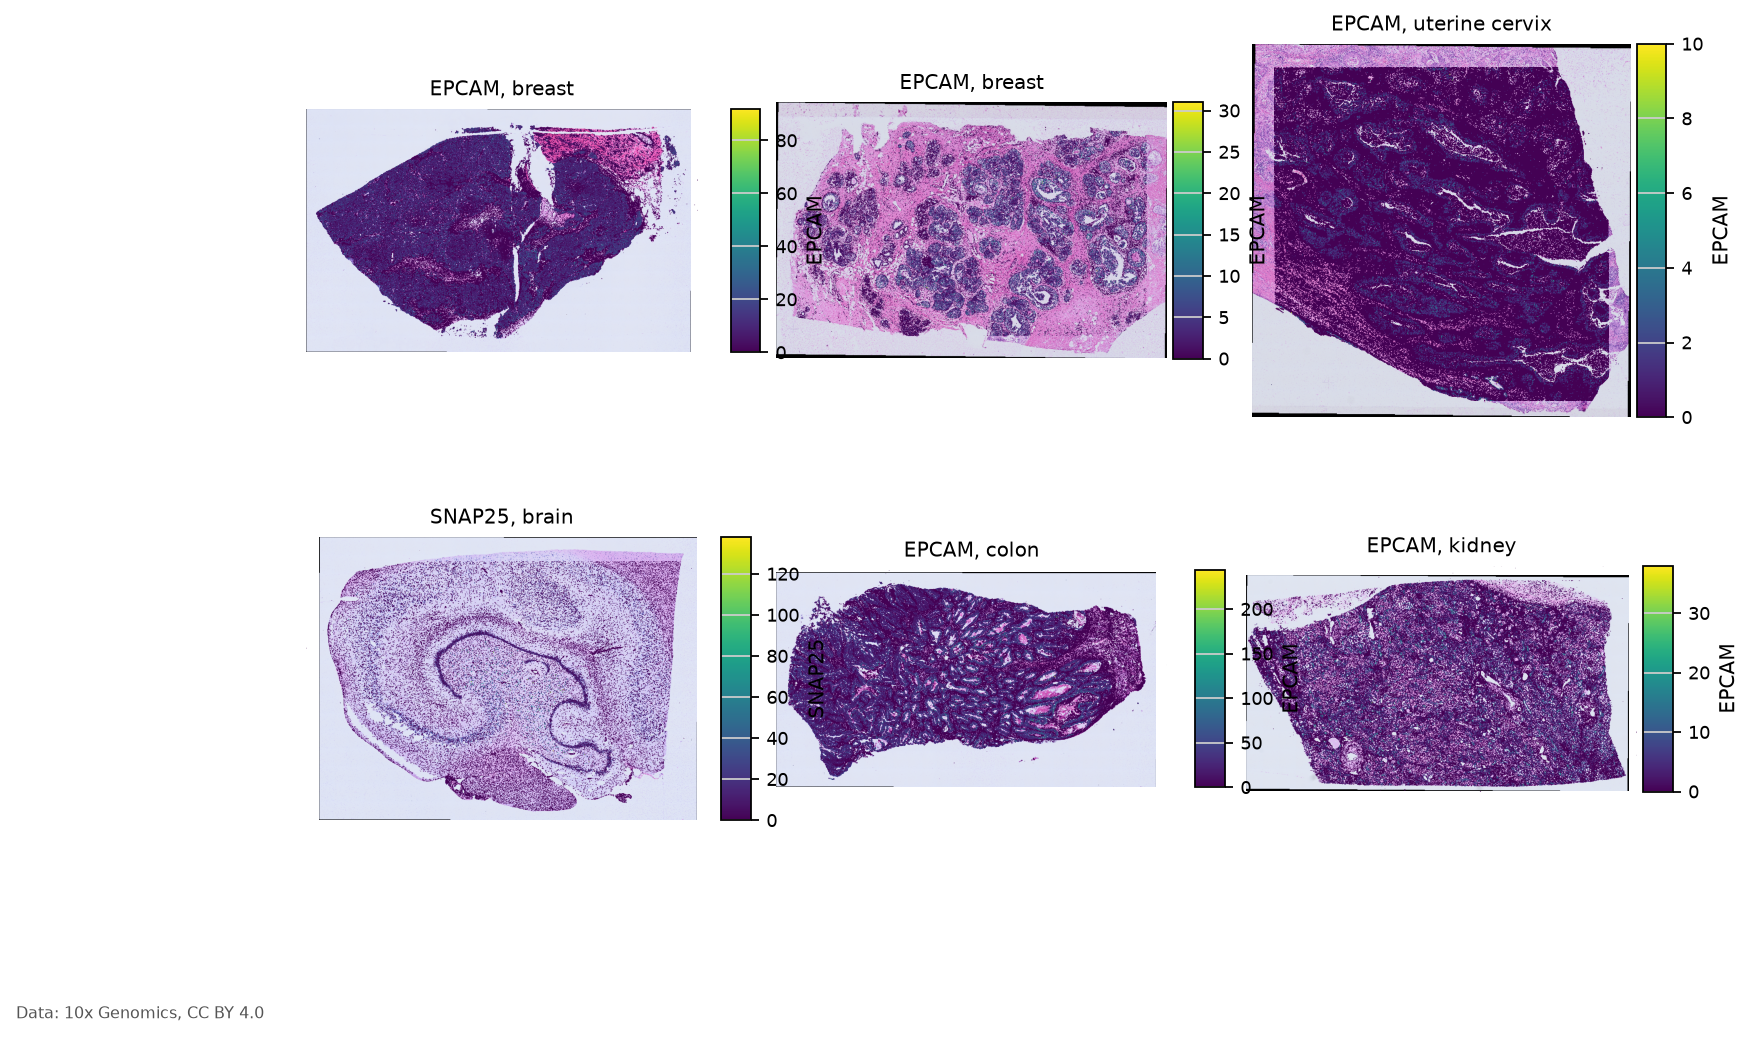

In [14]:
fig, axs = grid()
for ax, (u, s) in zip(axs, sdatas.items()):
    tissue = cohort.set_index("uid").loc[u, "tissue"]
    gene = "SNAP25" if "brain" in str(tissue) or "hippocamp" in str(tissue) else "EPCAM"
    region = shapes_table(s)
    if region is None:
        ax.set_axis_off()
        continue
    p = s.pl.render_images("he_image") if "he_image" in s.images else s
    p.pl.render_shapes(region, color=gene, table_name="table", cmap="viridis", method="datashader", fill_alpha=1.0).pl.show(ax=ax, title=f"{gene}, {tissue}")
    ax.set_axis_off()
credit(fig)
fig.savefig(OUT / "fig_gene_on_tissue.png", dpi=150, facecolor="white", bbox_inches="tight")

## Site tables

The run also writes the tables behind the collection page: UMAP coordinates of every cell before and after
Harmony, a 100,000-cell sample with an equal share per section, QC per section, the cohort and the manifest of the
run, and the integrated AnnData.

In [15]:
um = pd.DataFrame({"cell": adata.obs_names, "dataset": adata.obs["dataset"].astype(str).values, "tissue": adata.obs["tissue"].astype(str).values,
                   "preservation": adata.obs["preservation"].astype(str).values, "leiden": adata.obs["leiden"].astype(str).values,
                   "cell_type": adata.obs["cell_type"].astype(str).values,
                   "umap_raw_1": adata.obsm["X_umap_raw"][:, 0], "umap_raw_2": adata.obsm["X_umap_raw"][:, 1],
                   "umap_1": adata.obsm["X_umap"][:, 0], "umap_2": adata.obsm["X_umap"][:, 1]})
um.to_parquet(OUT / "umap_all_cells.parquet", index=False)
rng = np.random.default_rng(SEED)
per = SAMPLE // um["dataset"].nunique()
sample = pd.concat([d.iloc[rng.choice(len(d), min(per, len(d)), replace=False)] for _, d in um.groupby("dataset")])
sample.to_json(OUT / "umap_sample_100k.json", orient="records")
adata.write_h5ad(OUT / "atera_integrated.h5ad")
manifest = {"catalog_version": None if (ROWS or ZARRS) else CATALOG_VERSION, "pre_release_rows": ROWS, "cache": "hit" if HIT else "miss", "sddb": sddb.__version__, "rapids_singlecell": rsc.__version__, "scanpy": version("scanpy"),
            "spatialdata": sd.__version__, "datasets": cohort.to_dict("records"), "n_cells": int(adata.n_obs), "n_genes_joint": len(genes),
            "seed": SEED, "credit": CREDIT}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=1, default=str))
print(len(um), "cells;", len(sample), "in the sample")

2035360 cells; 99996 in the sample


## Reproduce

The heavy steps (quality control, variable genes, scaling, PCA, Harmony, neighbours, UMAP and Leiden) ran once,
in a run of about 28 minutes on one NVIDIA H100 GPU, on catalog release 2026-11-12, and wrote their result to `OUT/cache`. The
outputs shown here were rendered from that cache: the notebook loads it when the section uids and the rules match
the stored ones, and recomputes everything otherwise. To rerun, on a Linux machine with an NVIDIA GPU (CUDA 13
driver), from the repository root:

```
bash docs/primers/run_primer.sh atera
```

The script uses the locked environment (`pixi run --frozen`) and refuses a notebook above 20 MB. The environment is
pinned in `pixi.lock`, and the catalog release in `CATALOG_VERSION` above, so the same sections and counts come
back. Data: 10x Genomics, CC BY 4.0.